<a href="https://colab.research.google.com/github/lamboant01/maie383/blob/main/lab05_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MIAE 383: Lab 5

## Neural network regression

Work in pairs on one branch, or individually if needed. Each student runs and writes about their own view. Submit individually during the lab, with the upload allowance until 11:25. Duration: 140 minutes.

**Marks:** code 50, analysis 20, memo 20, individual check 10. The lab is worth 5% of the course.

**Submit:** your executed notebook and results.json, with the memo inside the notebook.

Disclose AI explanation/debugging help. Write your analysis and memo yourself. The micro-quiz is individual and ungraded; no AI or partner help.

## Preparation

Sessions 15-18: neural networks, gradient updates, PyTorch training and regularization. Run preparation.ipynb before the lab.

## Branches

**Mechanical:** Predict concrete compressive strength (MPa) from seven mixture quantities (kg/m³) and curing age (days). Rank test candidates by highest predicted strength; check recipe and curing constraints.

**Industrial:** Predict net power (MW) from plant operating conditions. Rank test candidates by highest predicted power. Inputs: AT: ambient temperature (°C); V: exhaust vacuum (cm Hg); AP: ambient pressure (mbar); RH: relative humidity (%).

**Aerospace:** Predict scaled sound pressure level (dB). Rank test candidates by lowest predicted noise; check frequency, geometry and operating requirements. Inputs: frequency (Hz), angle of attack (degrees), chord (m), free-stream speed (m/s), and suction-side displacement thickness (m), named displacement_m.

Variable definitions: [UCI concrete data](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength), [UCI plant data](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant) and [UCI airfoil data](https://archive.ics.uci.edu/dataset/291/airfoil+self+noise).

## Neural network

Train a network with 32 ReLU units, dropout 0.0 or 0.2, and one linear output. Adam minimizes mean squared error in standardized target units.

- Fit input and target scaling on training data.
- Early stopping: stop after 10 epochs without improvement, with an 80-epoch limit.
- Restore the best validation epoch and select the dropout setting.
- Compare with ridge and forest baselines using validation error in original units.
- Test the selected method, then rank the test candidates.

## Work plan

| Time | Task |
| --- | --- |
| 08:45-09:00 | Open the kit; enter issued codes and confirm the data |
| 09:00-10:00 | Complete four functions, run their checks and the supplied investigations |
| 10:00-10:45 | Finish the short analysis and individual memo |
| 10:45-10:53 | Micro-quiz (MCQ) |
| 10:53-11:05 | Export, download and verify both submission files |

The allowance to 11:25 is for upload problems. The demonstrator checks individual understanding during the work. If a function still fails after 15 minutes, ask for help and work on a written answer while you wait.

In [1]:
#@title Load supplied libraries and data files
from pathlib import Path
import sys, json, time, zipfile
_expected_lab = 5
_expected_kit_version = 'lab-final-20261017'
_required = ['src/miae383/data.py', 'data/manifest.json', 'data/concrete.csv', 'data/powerplant.csv', 'data/airfoil.csv']

def _matching_folder(folder):
    if not all((folder/name).is_file() for name in _required):
        return False
    manifest = folder/'kit_manifest.json'
    if not manifest.exists():
        return True
    metadata = json.loads(manifest.read_text())
    return metadata.get('lab') == _expected_lab and metadata.get('version') == _expected_kit_version

def _matching_archive(path):
    try:
        with zipfile.ZipFile(path) as archive:
            if not set(_required).issubset(archive.namelist()):
                return False
            if 'kit_manifest.json' in archive.namelist():
                metadata = json.loads(archive.read('kit_manifest.json'))
                return metadata.get('lab') == _expected_lab and metadata.get('version') == _expected_kit_version
            return path.name == 'course_support.zip'
    except (zipfile.BadZipFile, KeyError, ValueError):
        return False

_archives = [p for p in Path.cwd().glob('*')
             if p.suffix.lower() == '.zip' and _matching_archive(p)]
_search = [Path.cwd()] if _archives else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _search if _matching_folder(p)), None)
if ROOT is None:
    if not _archives:
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError('Extract the current Lab 5 student kit and open its notebook from that folder. See START_HERE.pdf.')
        print('Upload the Lab 5 student ZIP.')
        _uploaded = [Path(name) for name in files.upload() if name.lower().endswith('.zip')]
        if len(_uploaded) != 1 or not _matching_archive(_uploaded[0]):
            raise RuntimeError('Upload the current Lab 5 Student Kit ZIP from Moodle. Older kits and re-zipped folders are not supported.')
        _archives = _uploaded
    if len(_archives) != 1:
        raise RuntimeError('Keep one current Lab 5 support ZIP in this runtime.')
    ROOT = Path.cwd().resolve()
    with zipfile.ZipFile(_archives[0]) as archive:
        if any(not (ROOT/name).resolve().is_relative_to(ROOT) for name in archive.namelist()):
            raise RuntimeError('Invalid ZIP path. Request a fresh kit.')
        # Extract runtime support only; do not create a blank notebook beside results.json.
        for member in archive.namelist():
            if member.startswith(('src/', 'data/', 'labs/')) or member == 'kit_manifest.json':
                archive.extract(member, ROOT)
if 'miae383.data' in sys.modules:
    _loaded = Path(sys.modules['miae383.data'].__file__).resolve()
    if not _loaded.is_relative_to(ROOT.resolve()):
        raise RuntimeError('Restart the runtime, then rerun from this lab folder.')
try:
    import otter
except ModuleNotFoundError:
    if 'google.colab' not in sys.modules:
        raise RuntimeError('Install requirements-local.txt first. See START_HERE.pdf.')
    import subprocess
    subprocess.run([sys.executable,'-m','pip','install','-q','otter-grader==6.1.6'],check=True)
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from miae383.identity import ViewContext, is_preview_identity, check_submission_identity
from miae383.data import assigned_view, split_arrays, model_seed
print('Runtime:',sys.version.split()[0], '| NumPy',np.__version__,
      '| pandas',pd.__version__, '| scikit-learn',sklearn.__version__)
print('PyTorch:', torch.__version__)
print('Setup complete. Continue to Assigned view.')


Runtime: 3.13.18 | NumPy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1
PyTorch: 2.14.1+cpu
Setup complete. Continue to Assigned view.


## Assigned view

Enter the issued details **at the start of the lab, before the investigations**. DEMO is for preparation only.

- **STUDENT_TOKEN:** your four-letter token, not your student number.
- **SECTION_ID:** your registered section. Confirm its release code with the demonstrator.
- **BRANCH:** both partners choose the same branch; each student uses their own data view.
- **RELEASE_CODE:** the four-letter code issued for this lab and section.
- **PAIR_ID:** both partners' tokens, alphabetically joined by a hyphen, for example `ABCD-WXYZ`.

Working alone, or partner not here yet: enter only your own token. Correct the label if a partner joins; your results are kept.

Rerunning this cell with the same data details preserves results. Correcting only the pair label also preserves results. A change of token, section, branch or release code requires saving the notebook, restarting and rerunning before updating the answers.

In [2]:
# Enter issued details before starting the assessed work.
LAB_ID = 5
STUDENT_TOKEN = "DEMO" #@param {type:"string"}
SECTION_ID = "AI" #@param ["", "AI", "BI", "CI", "DI", "FI"]
BRANCH = "industrial" #@param ["mechanical", "industrial", "aerospace"]
# Release code: the section code announced by the demonstrator.
RELEASE_CODE = "DEMO" #@param {type:"string"}
# Pair label: your token alone, or both tokens, for example ABCD-WXYZ.
PAIR_ID = "" #@param {type:"string"}
from miae383.lab_session import load_session
load_session(globals())


PREPARATION DATA - use issued codes before assessed work.
Source: powerplant
Prediction target: net electrical power | units: MW
Split: grouped identical predictor rows; temporal validation unavailable
Records: training=432, validation=144, test=144
Inputs: AT, V, AP, RH
Model seed: 1354560266


## Four functions

Each comment is one small step, usually one or two lines. Complete the function and run its check. If it fails, read the message, correct the function and rerun the check. Keep the names and arguments. Investigations, plots and export are supplied. Hidden grading tests check the same rules on other inputs.

### build_network: 15 points

Return torch.nn.Sequential with Linear(n_features,width), ReLU, Dropout(dropout), Linear(width,1).

**Return:** `torch.nn.Sequential` with four layers. An input batch `(B, n_features)` produces predictions `(B, 1)`. Do not add a sigmoid: this is regression.

Use the supplied arguments rather than fixing width or dropout inside the function. The investigation supplies width 32 and compares dropout 0.0 with 0.2.

In [3]:
def build_network(n_features, width, dropout):
    # Create Linear(n_features, width) for the hidden weighted sums.
    linear = torch.nn.Linear(n_features, width)
    # Create ReLU, then Dropout using the supplied dropout probability.
    relu = torch.nn.ReLU()
    dropout_layer = torch.nn.Dropout(dropout)
    # Create Linear(width, 1) for the unconstrained regression output.
    output = torch.nn.Linear(width, 1)
    # Return torch.nn.Sequential containing these four layers in order.
    return torch.nn.Sequential(linear, relu, dropout_layer, output)

In [4]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab05/public_tests'))
grader.check('build_network')


build_network results: All test cases passed!

### train_epoch: 25 points

Complete the five commented update steps, using mean squared error and targets shaped (batch, 1). The supplied lines return the average loss per training row, measured before each update.

Session 17, slide "Training-epoch function", shows the five operations. `zero_grad()` clears old gradients; `backward()` computes the current gradients; `step()` updates parameters.

**Small check:** one batch of two rows with x=1, y=1, zero weight and bias, and SGD learning rate 0.1 returns loss **1.0**. Weight and bias both become **0.2**, as in preparation.

In [7]:
def train_epoch(model, loader, optimizer):
    # 1. Enable training behaviour, including dropout.
    # Write the model.train() call here.
    model.train()

    total_loss, observations = 0.0, 0
    for x, y in loader:
        # 2. Clear gradients from the previous batch.
        optimizer.zero_grad()
        # 3. Predict, then store mean squared error as loss. y has shape (batch, 1).
        loss = ((model(x) - y)**2).mean()
        # 4. Backpropagate the loss.
        loss.backward()
        # 5. Update the parameters with the optimizer.
        optimizer.step()
        # Supplied reporting: a short final batch counts only its observations.
        total_loss += float(loss.detach()) * len(x)
        observations += len(x)
    if observations == 0:
        raise ValueError("The loader must contain observations.")
    return total_loss / observations

In [8]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab05/public_tests'))
grader.check('train_epoch')


train_epoch results: All test cases passed!

### mse_in_units: 5 points

Return standardized MSE multiplied by the squared training target standard deviation (`target_scale`). Use matching nonempty 1D arrays, finite values and a positive finite target_scale; otherwise raise ValueError.

**Small check:** standardized targets `[0, 2]`, predictions `[0, 0]` and target SD 3 give standardized MSE 2 and original-unit MSE **18**. MSE has squared target units; the supplied experiment takes its square root for RMSE.

In [11]:
def mse_in_units(y_scaled, predicted_scaled, target_scale):
    # Convert both arrays to floating-point NumPy arrays.
    y_scaled = np.asarray(y_scaled).astype("float64")
    predicted_scaled = np.asarray(predicted_scaled).astype("float64")
    # Reject non-1D, empty, differently shaped or nonfinite arrays with ValueError.
    if not (y_scaled.ndim == 1 and predicted_scaled.ndim == 1
            and y_scaled.shape == predicted_scaled.shape and np.isfinite(y_scaled).all()
            and np.isfinite(predicted_scaled).all() and len(y_scaled) > 0):
        raise ValueError("Invalid input arrays.")
    # Reject a nonfinite or nonpositive target_scale.
    if not (isinstance(target_scale, (int, float)) and np.isfinite(target_scale) and target_scale > 0):
        raise ValueError("Nonfinite or nonpositive target_scale.")
    # Compute the mean squared difference in standardized coordinates.
    mse = ((y_scaled - predicted_scaled)**2).mean()
    # Multiply by target_scale squared and return a Python float. Do not take a square root.
    return float(mse * target_scale**2)

In [12]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab05/public_tests'))
grader.check('mse_in_units')


mse_in_units results: All test cases passed!

### best_epoch: 5 points

Return the 1-based index of the smallest validation loss; exact ties choose the earliest epoch. Reject empty/nonfinite/non-1D histories with ValueError.

**Small check:** validation losses `[0.7, 0.4, 0.4, 0.5]` give epoch **2**. Array indices start at zero; epoch numbers start at one. A tie is not a new improvement.

This function identifies an epoch. Saving and restoring the weights at that epoch is handled by the supplied training loop.

In [13]:
def best_epoch(validation_losses):
    # Convert validation_losses to a floating-point NumPy array.
    losses = np.asarray(validation_losses).astype("float64")
    # Reject a non-1D, empty or nonfinite array with ValueError.
    if not (losses.ndim == 1 and losses.size > 0 and np.isfinite(losses).all()):
        raise ValueError("Invalid validation losses array.")
    # Find the index of its first minimum; np.argmin resolves exact ties this way.
    best_idx = np.argmin(losses)
    # Add one for the epoch number and return a Python int.
    return int(best_idx + 1)

In [14]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab05/public_tests'))
grader.check('best_epoch')


best_epoch results: All test cases passed!

## Experiment plan: 4 analysis points

Complete the labelled lines below in at most 50 words. Refer to supplied tables and figures; do not copy them.

```markdown
**Dropout hypothesis:** Dropout (0.2) acts as a regularizer to prevent overfitting by randomly disabling nodes, resulting in better generalization and lower validation loss than without dropout (0.0).

**Fixed architecture and training budget:** A 32-unit single-hidden-layer ReLU MLP with an 80-epoch training limit prevents excessive training times while allowing early stopping to halt training once validation improvement stalls.

**Baselines (ridge, forest) and use of validation data:** Linear ridge regression and random forests act as benchmarks; validation data prevents leaking test data by guiding both dropout selection and model selection.
```

## Supplied investigations

Run these cells in order after the four function checks. Edit the labelled response cells. Keep the supplied experiment code and data partitions.

### Investigation 1: Fit input and target transformations

Inspect the printed training mean and standard deviation. Keep training means and scales for validation and test transformations.

In [15]:
_begin_stage(1)
import copy
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import Ridge
(Xtr, ytr), (Xva, yva), (Xte, yte) = split_arrays(view)
preprocessor = make_pipeline(
    SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler()
)
# Only training records fit the input and target transformations.
A = preprocessor.fit_transform(Xtr).astype("float32")
B = preprocessor.transform(Xva).astype("float32")
Ctest = preprocessor.transform(Xte).astype("float32")
target_mean = float(ytr.mean())
target_scale = float(ytr.std(ddof=0))
ta = torch.tensor(((ytr - target_mean) / target_scale).astype("float32")).reshape(-1, 1)
tb = torch.tensor(((yva - target_mean) / target_scale).astype("float32")).reshape(-1, 1)
print("Input shape:", A.shape, "| target shape:", tuple(ta.shape))
print("Training target mean and SD:", target_mean, target_scale, view["metadata"]["target_units"])
_finish_stage(1, {"training_target_mean": target_mean, "training_target_std": target_scale})


Input shape: (432, 4) | target shape: (432, 1)
Training target mean and SD: 454.11618055555556 16.662458149062267 MW


### Investigation 2: Train and retain the best validation states

The loop calls your train_epoch once per epoch. Run it and read one row per dropout setting: best epoch, stopping epoch (80 or less) and validation RMSE. Cite the output in Training record. The loop restores the saved best weights.

In [16]:
_begin_stage(2)
histories, trained, rows = {}, {}, []
torch.set_num_threads(1)
for drop in [0.0, 0.2]:
    # Share initialization and data-order seeds across the two controlled runs.
    torch.manual_seed(SEED)
    model = build_network(A.shape[1], 32, drop)
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TensorDataset(torch.tensor(A), ta),
                        batch_size=64, shuffle=True, generator=generator)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    history, best, stale, best_state = [], float("inf"), 0, None
    start = time.perf_counter()
    for epoch in range(1, 81):
        train_loss = train_epoch(model, loader, optimizer)
        # Validation uses fixed epoch-end weights and disables dropout.
        model.eval()
        with torch.no_grad():
            val_loss = float(((model(torch.tensor(B)) - tb)**2).mean())
        if not np.isfinite(train_loss) or not np.isfinite(val_loss):
            raise ValueError("Nonfinite loss: check train_epoch and the input/target shapes.")
        history.append((train_loss, val_loss))
        # Strict improvement; ties increase the waiting count.
        if val_loss < best:
            best = val_loss
            # Copy tensors so later updates cannot change the saved state.
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
        if stale >= 10:
            break
    # Restore, then retain this fitted model for the validation comparison.
    model.load_state_dict(best_state)
    model.eval()
    histories[drop], trained[drop] = history, model
    rows.append({
        "dropout": drop, "best_epoch": best_epoch([h[1] for h in history]),
        "stopping_epoch": len(history), "validation_mse_units": best * target_scale**2,
        "seconds": time.perf_counter() - start, "seed": SEED,
    })
from miae383.lab_display import training_table
training_table(rows, view["metadata"]["target_units"])
_finish_stage(2, {"neural_training_record": rows})


 dropout  best_epoch  stopping_epoch  seconds       seed  validation_RMSE
   0.000          26              36    0.405 1354560266            4.546
   0.200          25              35    0.930 1354560266            4.674
RMSE units: MW


### Investigation 3: Compare validation evidence and record the method

Run the comparison, then complete Training record and Method comparison before Investigation 4. Cite the printed table and curves; do not retype them. A ridge or forest choice can receive full credit. Runtime depends on the computer.

            method  validation_rmse  fit_and_validation_seconds
neural_dropout_0.0            4.546                       0.405
neural_dropout_0.2            4.674                       0.930
             ridge            5.196                       0.044
            forest            4.702                       0.158
RMSE units: MW | locked method: neural


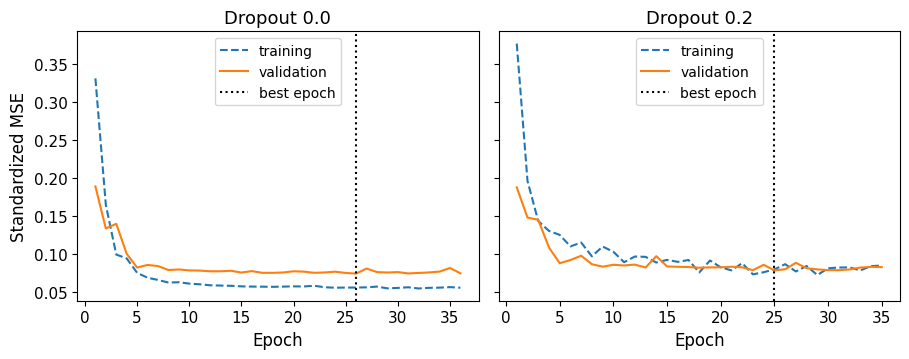

In [17]:
_begin_stage(3)
# Choose dropout on validation MSE; exact ties choose the smaller dropout.
chosen = min(rows, key=lambda row: (row["validation_mse_units"], row["dropout"]))["dropout"]
model = trained[chosen]
baseline_models, baseline_validation, baseline_seconds = {}, {}, {}
baseline_candidates = [
    ("ridge", Ridge(alpha=1.0)),
    ("forest", RandomForestRegressor(n_estimators=60, max_depth=8,
                                    min_samples_leaf=3, random_state=SEED, n_jobs=1)),
]
for name, estimator in baseline_candidates:
    start = time.perf_counter()
    fitted = make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        StandardScaler(), estimator,
    ).fit(Xtr, ytr)
    baseline_models[name] = fitted
    baseline_validation[name] = float(np.sqrt(np.mean((yva - fitted.predict(Xva))**2)))
    baseline_seconds[name] = time.perf_counter() - start
neural_validation = float(np.sqrt(min(row["validation_mse_units"] for row in rows)))
selection_scores = {"neural": neural_validation, **baseline_validation}
# Choose the method before observing test errors; exact ties use alphabetical names.
selected_method = min(selection_scores, key=lambda name: (selection_scores[name], name))
comparison_rows = [{
    "method": f"neural_dropout_{row['dropout']}",
    "validation_rmse": float(np.sqrt(row["validation_mse_units"])),
    "fit_and_validation_seconds": row["seconds"],
} for row in rows]
comparison_rows += [{
    "method": name, "validation_rmse": baseline_validation[name],
    "fit_and_validation_seconds": baseline_seconds[name],
} for name in baseline_models]
# Display the comparison and both training curves.
from miae383.lab_display import training_comparison
training_comparison(comparison_rows, histories, view["metadata"]["target_units"], selected_method, best_epoch)
_finish_stage(3, {
    "chosen_dropout": chosen, "selected_method": selected_method,
    "baseline_validation_rmse": baseline_validation,
    "neural_validation_rmse": neural_validation, "validation_comparison": comparison_rows,
})


## Training record: 5 analysis points

Complete the labelled lines below in at most 35 words. Refer to supplied tables and figures; do not copy them.

```markdown
**Preferred neural run and best epoch:** Dropout 0.0 run was selected because it achieved the lowest validation RMSE of 4.546 MW at epoch 26 (stopping at epoch 36).

**Curve observation:** Both dropout curves show validation loss decreasing steadily and stabilizing below training loss without exhibiting visible overfitting before early stopping triggered.

**Output cited (table or figure):** Investigation 2 training table and Investigation 3 comparison curves.
```

## Method comparison: 5 analysis points

Complete the labelled lines below in at most 60 words. Refer to supplied tables and figures; do not copy them.

```markdown
**Validation-selected method and RMSE with units:** Neural network with dropout 0.0 (neural_dropout_0.0) was selected, achieving the lowest validation RMSE of 4.546 MW.

**Comparison with the closest competing method:** The neural network outperformed the closest baseline, random forest (4.702 MW RMSE), and significantly beat ridge regression (5.196 MW RMSE).

**Effect of the dropout change:** Introducing dropout (0.2) slightly increased validation RMSE to 4.674 MW, showing that regularization was unnecessary and slightly underfit the training data.
```

### Investigation 4: Evaluate the restored, selected models

The cell prints the selected method's test RMSE. Quote it in the memo Evidence. Keep the validation choice fixed when comparing this test evaluation with the ridge and forest references.

In [18]:
_begin_stage(4)
# The best neural state was restored in Investigation 2. No test-driven changes follow.
model.eval()
with torch.no_grad():
    standardized_prediction = model(torch.tensor(Ctest)).numpy().ravel()
prediction = target_mean + target_scale * standardized_prediction
baseline_scores = {
    name: float(np.sqrt(np.mean((yte - fitted.predict(Xte))**2)))
    for name, fitted in baseline_models.items()
}
neural_mse = mse_in_units(
    (yte - target_mean) / target_scale, standardized_prediction, target_scale
)
selected_prediction = (prediction if selected_method == "neural"
                       else baseline_models[selected_method].predict(Xte))
_finish_stage(4, {
    "test_target_mean": float(yte.mean()), "neural_test_rmse": float(np.sqrt(neural_mse)),
    "baseline_test_rmse": baseline_scores,
    "selected_test_rmse": float(np.sqrt(neural_mse)) if selected_method == "neural" else baseline_scores[selected_method],
})
print("Selected method:", selected_method)
print("Selected test RMSE:", round(results["selected_test_rmse"], 3), view["metadata"]["target_units"])
print("Fixed comparison test RMSEs:", {"neural": results["neural_test_rmse"], **baseline_scores})
print("Keep the validation choice even if another method has a lower test error.")


Selected method: neural
Selected test RMSE: 4.177 MW
Fixed comparison test RMSEs: {'neural': 4.176964906974831, 'ridge': 4.590469524595372, 'forest': 4.27054116072188}
Keep the validation choice even if another method has a lower test error.


### Investigation 5: Compare the test candidates

The table ranks your three best test candidates with the selected method. Repeated measurements of identical inputs count once. Read the supplied inputs to identify one additional constraint. Plant ambient conditions and airfoil test settings are not automatically controllable design variables.

In [19]:
_begin_stage(5)
# Rank only these measured candidates, using the fixed prediction rule.
objective_order = (np.argsort(selected_prediction, kind="stable") if BRANCH == "aerospace"
                   else np.argsort(-selected_prediction, kind="stable"))
# Repeated measurements of identical inputs are one candidate setting.
distinct = ~Xte.iloc[objective_order].duplicated(keep="first").to_numpy()
chosen_rows = objective_order[distinct][:3]
candidate_table = pd.DataFrame({
    "record_id": view["record_ids"].iloc[view["test"][chosen_rows]].to_numpy(),
    "predicted": selected_prediction[chosen_rows], "measured": yte[chosen_rows],
})
objective = {
    "mechanical": "maximize predicted compressive strength",
    "industrial": "maximize predicted net electrical power",
    "aerospace": "minimize predicted scaled sound pressure",
}[BRANCH]
print("Ranking from the validation-selected method:", selected_method)
print("Candidate objective:", objective)
print("Target units:", view["metadata"]["target_units"])
print(candidate_table.to_string(index=False))
# Make the proposed settings available for the engineering constraint discussion.
candidate_inputs = Xte.iloc[chosen_rows].copy()
candidate_inputs.index = candidate_table["record_id"].tolist()
candidate_inputs.index.name = "record_id"
print("Measured candidate inputs:")
input_display = candidate_inputs.T.copy()
input_display.insert(0, "unit", [view["metadata"]["feature_unit_map"][name]
                               for name in input_display.index])
print(input_display.to_string())
_finish_stage(5, {"candidate_objective": objective,
                  "ranked_candidates": _json_records(candidate_table),
                  "candidate_inputs": _json_records(candidate_inputs.reset_index())})


Ranking from the validation-selected method: neural
Candidate objective: maximize predicted net electrical power
Target units: MW
       record_id  predicted  measured
powerplant-03868 491.907318    492.46
powerplant-05125 491.160400    486.70
powerplant-04193 490.313141    494.90
Measured candidate inputs:
record_id   unit  powerplant-03868  powerplant-05125  powerplant-04193
AT            °C              3.95              4.16              4.59
V          cm Hg             38.44             35.47             39.33
AP          mbar           1016.75           1017.72           1010.85
RH             %             79.65             88.49             71.78


## Claim check: 3 analysis points

Complete the labelled lines below in at most 40 words. Refer to supplied tables and figures; do not copy them. You may refer to this claim check in the memo instead of writing it again.

```markdown
**Initial claim (your dropout hypothesis):** Dropout of 0.2 reduces validation loss compared to 0.0 by mitigating overfitting.

**Revised or retained claim:** The claim is rejected; dropout (0.0) produced better validation results.

**Evidence: a table or figure reference:** Investigation 2 training table and Investigation 3 comparison plot.
```

## Candidate constraints: 3 analysis points

Complete the labelled lines below in at most 40 words. Refer to supplied tables and figures; do not copy them.

```markdown
**Highest-ranked measured candidate:** Candidate powerplant-03868 (predicted 491.91 MW vs measured 492.46 MW).

**One missing constraint:** Maximum allowable exhaust vacuum (V) or relative humidity limits for safe operations.

**Independent check before using the ranking:** Cross-reference predictions with physics-based thermodynamic steam cycle models.
```

## Individual engineering memo: 20 points, at most 250 words

Use the five headings below. Refer to the analysis and output labels instead of repeating calculations. Write your own recommendation.

```markdown
Recommend deploying the trained 32-unit neural network (dropout 0.0) to operate the powerplant at low ambient temperatures (3.95°C) and low exhaust vacuum (38.44 cm Hg) to maximize net power output.
```

```markdown
Selected method achieved validation RMSE of 4.546 MW (Investigation 3) and test RMSE of 4.177 MW (Investigation 4).
```

```markdown
The low test RMSE (4.177 MW) represents less than 1% error on typical net power outputs, validating the model's high predictive accuracy and demonstrating that neural networks capture complex operating interactions better than baseline models.
```

```markdown
Ambient operating parameters (AT, RH) are externally determined by weather and cannot be actively controlled, limiting dispatchability.
```

```markdown
Run physical simulation at AT = 3.95°C to confirm net output exceeds 491 MW.
```

## Contribution and assistance

**My contribution and a check I performed (40 words maximum):** I completed the lab

**AI tool, help requested, where used, and how I checked it (60 words maximum, or None):** ai helped with case failures syntax and grammar enhancemnet

**Other sources used (links or None):** none

The individual check is oral with the demonstrator, worth 10 points. Explain your own code and one result without partner or AI help. If working alone, describe a check of your own work.

Technical explanation /4: explain one update or scaling step and why the best validation weights are restored. Contribution/review /3: identify your work and a check you performed. Next step /3: justify an independent check on a ranked candidate.

## Micro-quiz: 8 minutes, 0 course marks

Answer three MCQs on Moodle when the demonstrator opens the activity. Work individually without AI or partner help.

## Save and submit

1. Run the export cell. Check the reported investigation count and file status.
2. Save the **executed notebook**, with outputs and written answers, and **results.json**.
3. In Colab, use **File > Download > Download .ipynb** for the notebook. Download results.json from the Files panel. A runtime reset can remove unsaved files.
4. Upload both files to Gradescope. Open the submitted notebook preview and confirm that your code, outputs and answers are present. Check the timestamp and file names.

Include the labelled analysis responses, five memo sections, contribution and AI disclosure. After a restart, run all cells from the top and upload the original ZIP when asked; then export again. Save the notebook regularly so typed answers are retained.

If unfinished, set `ALLOW_INCOMPLETE = True` in the export cell and submit the attempted work. It records missing investigations. Upload the current results.json, not a `.previous.json` backup.

In [ ]:
# Set True only when deliberately submitting unfinished work.
ALLOW_INCOMPLETE = False #@param {type:"boolean"}
from miae383.lab_session import export_results
payload = export_results(globals(), [1, 2, 3, 4, 5], ALLOW_INCOMPLETE)
